# House Prices Prediction using TensorFlow Decision Forests

In [1]:
#packages used throughout this project
import pandas as pd
import numpy as np

import seaborn as sns
sns.set_style("whitegrid")
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.model_selection import cross_val_score, KFold, RandomizedSearchCV
from xgboost import XGBRegressor

C:\Users\tayef\anaconda3\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
#pip install xgboost

In [3]:
train_data=pd.read_csv("data/train.csv")
test_data=pd.read_csv("data/test.csv")

In [4]:
train_data=train_data.drop('Id', axis=1)
Ids=test_data.pop('Id')

In [5]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [6]:
num_data=train_data.select_dtypes(include=['float64', 'int64'])
num_data

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,62.0,7917,6,5,1999,2000,0.0,0,0,...,0,40,0,0,0,0,0,8,2007,175000
1456,20,85.0,13175,6,6,1978,1988,119.0,790,163,...,349,0,0,0,0,0,0,2,2010,210000
1457,70,66.0,9042,7,9,1941,2006,0.0,275,0,...,0,60,0,0,0,0,2500,5,2010,266500
1458,20,68.0,9717,5,6,1950,1996,0.0,49,1029,...,366,0,112,0,0,0,0,4,2010,142125


In [7]:
train_data.describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


<AxesSubplot:>

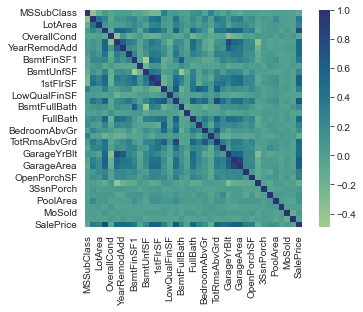

In [8]:
corr_matrix=num_data.corr()
sns.heatmap(corr_matrix, cmap="crest", square=True)

## House Price Distribution

Now, let us take a look at how the house prices are distributed.

In [9]:
train_data["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

C:\Users\tayef\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='SalePrice', ylabel='Density'>

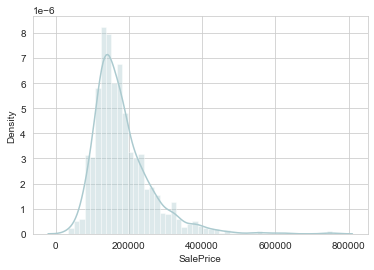

In [10]:
#Compared to the original notebook, I removed bins=100 and hist_kws={'alpha': 0.4}
sns.distplot(train_data["SalePrice"], color="#abcacf")

## Numerical data distribution

We will now take a look at how the numerical features are distributed. In order to do this, let us first list all the types of data from our dataset and select only the numerical ones.

In [11]:
num_data

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,62.0,7917,6,5,1999,2000,0.0,0,0,...,0,40,0,0,0,0,0,8,2007,175000
1456,20,85.0,13175,6,6,1978,1988,119.0,790,163,...,349,0,0,0,0,0,0,2,2010,210000
1457,70,66.0,9042,7,9,1941,2006,0.0,275,0,...,0,60,0,0,0,0,2500,5,2010,266500
1458,20,68.0,9717,5,6,1950,1996,0.0,49,1029,...,366,0,112,0,0,0,0,4,2010,142125


Now, let us plot the distribution for all the numerical features.

array([[<AxesSubplot:title={'center':'MSSubClass'}>,
        <AxesSubplot:title={'center':'LotFrontage'}>,
        <AxesSubplot:title={'center':'LotArea'}>,
        <AxesSubplot:title={'center':'OverallQual'}>,
        <AxesSubplot:title={'center':'OverallCond'}>,
        <AxesSubplot:title={'center':'YearBuilt'}>],
       [<AxesSubplot:title={'center':'YearRemodAdd'}>,
        <AxesSubplot:title={'center':'MasVnrArea'}>,
        <AxesSubplot:title={'center':'BsmtFinSF1'}>,
        <AxesSubplot:title={'center':'BsmtFinSF2'}>,
        <AxesSubplot:title={'center':'BsmtUnfSF'}>,
        <AxesSubplot:title={'center':'TotalBsmtSF'}>],
       [<AxesSubplot:title={'center':'1stFlrSF'}>,
        <AxesSubplot:title={'center':'2ndFlrSF'}>,
        <AxesSubplot:title={'center':'LowQualFinSF'}>,
        <AxesSubplot:title={'center':'GrLivArea'}>,
        <AxesSubplot:title={'center':'BsmtFullBath'}>,
        <AxesSubplot:title={'center':'BsmtHalfBath'}>],
       [<AxesSubplot:title={'center':'Ful

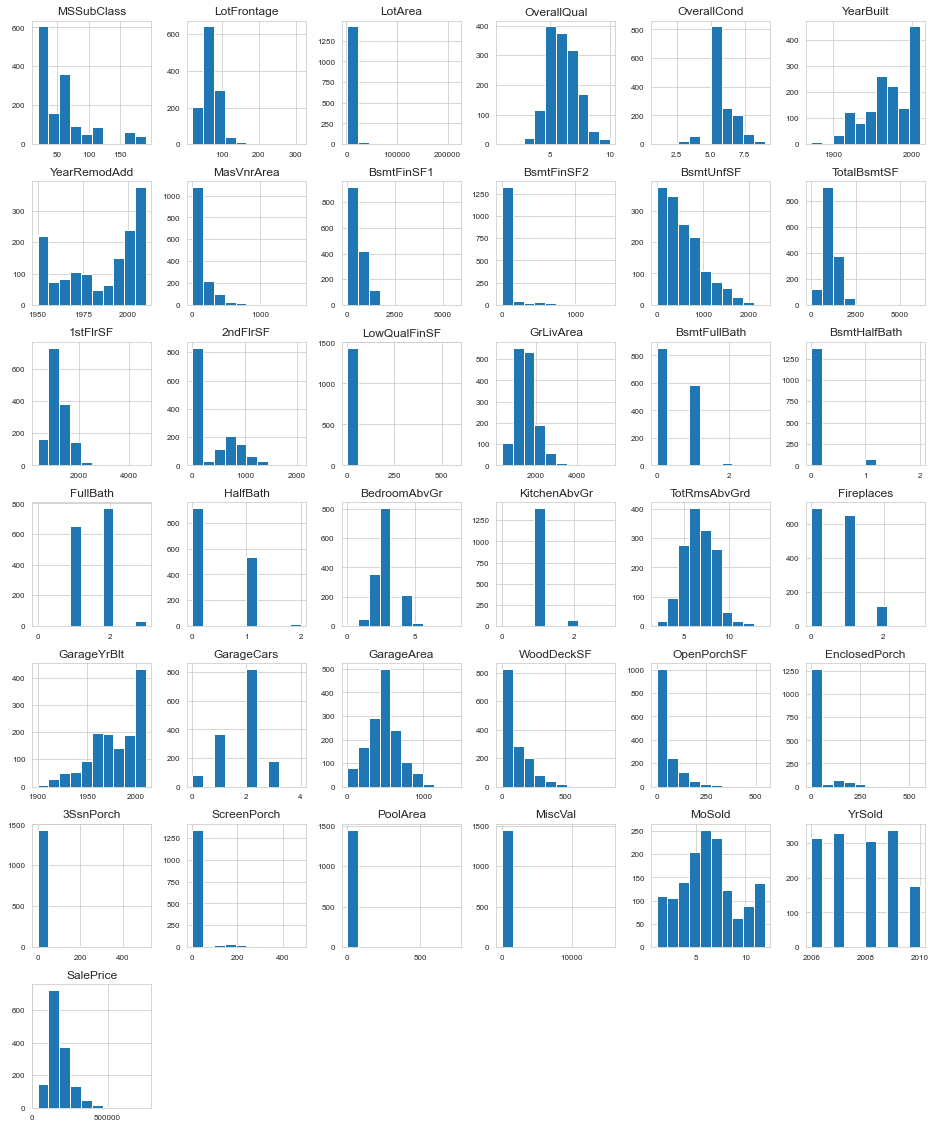

In [12]:
num_data.hist(figsize=(16, 20), xlabelsize=8, ylabelsize=8)

In [13]:
total_missing_values=train_data.isnull().sum().sort_values(ascending=False)
percentage=(train_data.isnull().sum()/train_data.isnull().count()).sort_values(ascending=False)
missing_values=pd.concat([total_missing_values, percentage], axis=1, keys=['Total', 'Percentage'])
missing_values=missing_values[missing_values['Total']>0]
missing_values

,Total,Percentage
PoolQC,1453,0.995205
MiscFeature,1406,0.963014
Alley,1369,0.937671
Fence,1179,0.807534
FireplaceQu,690,0.472603
LotFrontage,259,0.177397
GarageYrBlt,81,0.055479
GarageCond,81,0.055479
GarageType,81,0.055479
GarageFinish,81,0.055479


In [14]:
#we have to handle missing values
#PoolQC: Pool quality; NA means the property has no pool
train_data['PoolQC']=train_data['PoolQC'].fillna('No Pool')
test_data['PoolQC']=test_data['PoolQC'].fillna('No Pool')

#MiscFeature: Miscellaneous feature not covered in other categories; NA means no miscellaneous feature
train_data['MiscFeature']=train_data['MiscFeature'].fillna('No miscellaneous feature')
test_data['MiscFeature']=test_data['MiscFeature'].fillna('No miscellaneous feature')

#Alley: Type of alley access to property; NA means No alley access
train_data['Alley']=train_data['Alley'].fillna('No alley access')
test_data['Alley']=test_data['Alley'].fillna('No alley access')

#Fence: Fence quality; NA means No Fence
train_data['Fence']=train_data['Fence'].fillna('No Fence')
test_data['Fence']=test_data['Fence'].fillna('No Fence')

#FireplaceQu: Fireplace quality; NA means No Fireplace
train_data['FireplaceQu']=train_data['FireplaceQu'].fillna('No Fireplace')
test_data['FireplaceQu']=test_data['FireplaceQu'].fillna('No Fireplace')

In [15]:
#How I break down this relationship to fill in the missing values for LotFrontage
#missing_frontage=train_data[train_data["LotFrontage"].isna()][["LotFrontage", "LotConfig"]]
#missing_frontage.groupby("LotConfig")["LotFrontage"].size()

#missing_rate=train_data.groupby("LotConfig")["LotFrontage"].apply(lambda x: x.isna().mean())

#std_check=train_data.groupby("Neighborhood")["LotFrontage"].std()

#train_data["LotFrontage"].corr(train_data["LotArea"])
#train_data["LotFrontage"].corr(np.sqrt(train_data["LotArea"]))

In [16]:
#LotFrontage

#Combine LotArea (sqrt) + Neighborhood (one-hot) into one feature set
def build_features(df):
    features=pd.get_dummies(df['Neighborhood'], prefix='Nbhd')
    features['sqrt_LotArea']=np.sqrt(df['LotArea'])
    return features

#Build features for train and test separately, then align columns
#in case test_data has a neighborhood train_data doesn't, or vice versa
train_features=build_features(train_data)
test_features=build_features(test_data)
train_features, test_features=train_features.align(test_features, join='outer', axis=1, fill_value=0)

#Fit only on rows in train_data where LotFrontage is known
train_mask=train_data['LotFrontage'].notna()
X_train=train_features.loc[train_mask]
y_train=train_data.loc[train_mask, 'LotFrontage']

reg=LinearRegression()
reg.fit(X_train, y_train)

#Fill missing values in train_data
train_missing=train_data['LotFrontage'].isna()
if train_missing.sum()>0:
    train_data.loc[train_missing, 'LotFrontage']=reg.predict(train_features.loc[train_missing])

#Fill missing values in test_data using the same fitted model
test_missing=test_data['LotFrontage'].isna()
if test_missing.sum()>0:
    test_data.loc[test_missing, 'LotFrontage']=reg.predict(test_features.loc[test_missing])

#TIL: '' is used for strings so, don't stick to good old habits my dear; world is messy; move on
print("Train missing:", train_data['LotFrontage'].isna().sum())
print("Test missing:", test_data['LotFrontage'].isna().sum())

Train missing: 0
Test missing: 0


In [17]:
#BsmtFinType2 has 38 missing but BsmtQual/BsmtCond/BsmtFinType1 have 37
#there's a row that has a basement (so the other basement columns are filled in) but is missing BsmtFinType2
has_bsmt_no_fin2=train_data['BsmtQual'].notna() & train_data['BsmtFinType2'].isna()
print(train_data.loc[has_bsmt_no_fin2, ['BsmtQual','BsmtCond','BsmtFinType1','BsmtFinType2']])

    BsmtQual BsmtCond BsmtFinType1 BsmtFinType2
332       Gd       TA          GLQ          NaN


In [18]:
#filling just this one with the mode among houses with a basement
bsmt_fin2_mode=train_data.loc[train_data['BsmtQual'].notna(), 'BsmtFinType2'].mode()[0]

mask=train_data['BsmtQual'].notna() & train_data['BsmtFinType2'].isna()
train_data.loc[mask, 'BsmtFinType2']=bsmt_fin2_mode

print(train_data.loc[mask, ['BsmtQual','BsmtCond','BsmtFinType1','BsmtFinType2']])

    BsmtQual BsmtCond BsmtFinType1 BsmtFinType2
332       Gd       TA          GLQ          Unf


In [19]:
#Garage categoricals - no garage
garage_cat_cols=['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
for df in [train_data, test_data]:
    for col in garage_cat_cols:
        df[col]=df[col].fillna('No Garage')

#Basement categoricals - no basement
bsmt_cat_cols=['BsmtFinType2', 'BsmtExposure', 'BsmtQual', 'BsmtCond', 'BsmtFinType1']
for df in [train_data, test_data]:
    for col in bsmt_cat_cols:
        df[col]=df[col].fillna('No Basement')

#Masonry veneer - none
for df in [train_data, test_data]:
    df['MasVnrType']=df['MasVnrType'].fillna('None')
    df['MasVnrArea']=df['MasVnrArea'].fillna(0)

#Electrical - single missing value, use mode
mode_val= train_data['Electrical'].mode()[0]
for df in [train_data, test_data]:
    df['Electrical'] = df['Electrical'].fillna(mode_val)

In [20]:
#do this AFTER filling GarageType
for df in [train_data, test_data]:
    df['HasGarage']=(df['GarageType']!='No Garage').astype(int) 
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

In [21]:
total_missing_values=test_data.isnull().sum().sort_values(ascending=False)
percentage=(test_data.isnull().sum()/test_data.isnull().count()).sort_values(ascending=False)
missing_values=pd.concat([total_missing_values, percentage], axis=1, keys=['Total', 'Percentage'])
missing_values=missing_values[missing_values['Total']>0]
missing_values

,Total,Percentage
MSZoning,4,0.002742
BsmtFullBath,2,0.001371
BsmtHalfBath,2,0.001371
Functional,2,0.001371
Utilities,2,0.001371
Exterior1st,1,0.000685
BsmtFinSF2,1,0.000685
GarageCars,1,0.000685
GarageArea,1,0.000685
KitchenQual,1,0.000685


In [22]:
#1.Categorical columns: fill with train_data's mode
categorical_fill_cols=['MSZoning', 'Utilities', 'Functional', 'SaleType', 'Exterior1st', 'Exterior2nd', 'KitchenQual']

for col in categorical_fill_cols:
    if test_data[col].isna().sum()>0:
        mode_val=train_data[col].mode()[0]
        test_data[col]=test_data[col].fillna(mode_val)

#2. Numeric columns: fill with 0 (no basement / no garage cases)
zero_fill_cols=['BsmtHalfBath', 'BsmtFullBath', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFinSF2', 'BsmtFinSF1', 'GarageCars', 'GarageArea']

for col in zero_fill_cols:
    if test_data[col].isna().sum()>0:
        test_data[col]=test_data[col].fillna(0)

#Final check
remaining=test_data.isna().sum()
print(remaining[remaining>0])

Series([], dtype: int64)


In [23]:
#Feature Engineering
for df in [train_data, test_data]:
    df['TotalSF']=df['TotalBsmtSF']+df['1stFlrSF']+df['2ndFlrSF']
    df['TotalBath']=(df['FullBath']+0.5*df['HalfBath']+df['BsmtFullBath']+0.5*df['BsmtHalfBath'])
    df['HouseAge']=df['YrSold']-df['YearBuilt']
    df['RemodAge']=df['YrSold']-df['YearRemodAdd']
    df['IsRemodeled']=(df['YearBuilt']!=df['YearRemodAdd']).astype(int)
    df['HasPool']=(df['PoolQC']!='No Pool').astype(int)
    df['Has2ndFloor']=(df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace']=(df['FireplaceQu'] != 'No Fireplace').astype(int)

In [24]:
#Encoding

#1. Explicit ordinal mappings (from data_description.txt)
ordinal_maps = {
    'ExterQual':    {'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'ExterCond':    {'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'BsmtQual':     {'No Basement':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'BsmtCond':     {'No Basement':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'BsmtExposure': {'No Basement':0,'No':1,'Mn':2,'Av':3,'Gd':4},
    'BsmtFinType1': {'No Basement':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6},
    'BsmtFinType2': {'No Basement':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6},
    'HeatingQC':    {'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'KitchenQual':  {'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'FireplaceQu':  {'No Fireplace':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'GarageFinish': {'No Garage':0,'Unf':1,'RFn':2,'Fin':3},
    'GarageQual':   {'No Garage':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'GarageCond':   {'No Garage':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'PoolQC':       {'No Pool':0,'Fa':2,'TA':3,'Gd':4,'Ex':5},
    'Fence':        {'No Fence':0,'MnWw':1,'GdWo':2,'MnPrv':3,'GdPrv':4},
    'Functional':   {'Sal':1,'Sev':2,'Maj2':3,'Maj1':4,'Mod':5,'Min2':6,'Min1':7,'Typ':8},
    'LandSlope':    {'Sev':1,'Mod':2,'Gtl':3},
    'LotShape':     {'IR3':1,'IR2':2,'IR1':3,'Reg':4},
    'PavedDrive':   {'N':1,'P':2,'Y':3},
    'Utilities':    {'ELO':1,'NoSeWa':2,'NoSewr':3,'AllPub':4},
    'Street':       {'Grvl':1,'Pave':2},
    'CentralAir':   {'N':0,'Y':1},
}

#2. Force known "coded" nominal columns to be treated as categorical, not numeric
force_nominal=['MSSubClass']

for df in [train_data, test_data]:
    for col in force_nominal:
        df[col]=df[col].astype(str)
    for col, mapping in ordinal_maps.items():
        df[col]=df[col].map(mapping)

#3. Everything else splits automatically by dtype
target_col='SalePrice'
id_col='Id'

all_cols=[c for c in train_data.columns if c not in [target_col, id_col]]
ordinal_cols=list(ordinal_maps.keys())
nominal_cols=[c for c in all_cols if train_data[c].dtype == object and c not in ordinal_cols]
numeric_cols=[c for c in all_cols if c not in ordinal_cols and c not in nominal_cols]

print(f"Ordinal: {len(ordinal_cols)}, Nominal: {len(nominal_cols)}, Numeric: {len(numeric_cols)}")

Ordinal: 22, Nominal: 22, Numeric: 44


In [25]:
#Scaling and log transformation
from scipy.stats import skew

#log1p-transform right-skewed continuous features (helps Ridge/Lasso a lot, doesn't hurt trees)
skewed=train_data[numeric_cols].apply(lambda x: skew(x.dropna()))
skewed_cols=skewed[abs(skewed)>0.75].index.tolist()

for df in [train_data, test_data]:
    for col in skewed_cols:
        df[col]=np.log1p(df[col].clip(lower=0))

#log-transform the target too — standard for this dataset, and it's what RMSE-on-log
#competitions actually score against
train_data['SalePrice_log']=np.log1p(train_data['SalePrice'])

# Model Development

In [ ]:
X=train_data[ordinal_cols + numeric_cols + nominal_cols]
y=train_data['SalePrice_log']

preprocessor=ColumnTransformer(transformers=[
    ('num', StandardScaler(), ordinal_cols + numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), nominal_cols),
])

base_learners=[
    ('lasso', Lasso(alpha=0.0005, random_state=42, max_iter=10000)),
    ('ridge', Ridge(alpha=10, random_state=42)),
    ('rf', RandomForestRegressor(n_estimators=500, max_depth=None,
                                  min_samples_leaf=2, random_state=42, n_jobs=-1)),
    ('xgb', XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=4,
                          subsample=0.8, colsample_bytree=0.7,
                          random_state=42, n_jobs=-1)),
]

stack=StackingRegressor(
    estimators=base_learners,
    final_estimator=Ridge(alpha=1.0),
    #inner CV so the meta-learner trains on out-of-fold predictions, not leaked ones
    cv=5,          
    n_jobs=-1,
)

full_pipeline=Pipeline([
    ('preprocess', preprocessor),
    ('stack', stack),
])

#Evaluate with the same metric Kaggle scores on: RMSE of log(SalePrice)
kf=KFold(n_splits=5, shuffle=True, random_state=42)
scores=cross_val_score(full_pipeline, X, y, scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1)
print("CV RMSE (log scale):", -scores.mean(), "+/-", scores.std())

#Fit on full training data and predict on test
full_pipeline.fit(X, y)
test_preds_log=full_pipeline.predict(test_data[ordinal_cols + numeric_cols + nominal_cols])
#back-transform from log scale
test_preds=np.expm1(test_preds_log)

CV RMSE (log scale): 0.12125720037145218 +/- 0.02084142012287088


In [ ]:
#Claude: Each base learner was tuned to minimize its own individual RMSE in isolation
#but a model that's individually "best" isn't necessarily the one that contributes most usefully to an ensemble
"""X=train_data[ordinal_cols + numeric_cols + nominal_cols]
y=train_data['SalePrice_log']

preprocessor=ColumnTransformer(transformers=[
    ('num', StandardScaler(), ordinal_cols + numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), nominal_cols),
])

kf=KFold(n_splits=5, shuffle=True, random_state=42)

#Step 1: Tune each base learner independently
#Each search runs on preprocessed features, so build a small pipeline per model

def tune_model(estimator, param_dist, name, n_iter=20):
    pipe=Pipeline([('preprocess', preprocessor), ('model', estimator)])
    search=RandomizedSearchCV(
        pipe, param_distributions=param_dist, n_iter=n_iter,
        scoring='neg_root_mean_squared_error', cv=kf,
        random_state=42, n_jobs=-1
    )
    search.fit(X, y)
    print(f"{name} best RMSE: {-search.best_score_:.4f}")
    print(f"{name} best params: {search.best_params_}\n")
    return search.best_params_

#Lasso
lasso_params=tune_model(
    Lasso(random_state=42, max_iter=20000),
    {'model__alpha': np.logspace(-5, -1, 30)},
    'Lasso'
)

#Ridge
ridge_params=tune_model(
    Ridge(random_state=42),
    {'model__alpha': np.logspace(-1, 2, 30)},
    'Ridge'
)

#Random Forest
rf_params=tune_model(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    {
        'model__n_estimators': [300, 500, 800],
        'model__max_depth': [None, 10, 20, 30],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 0.5, 1.0],
    },
    'Random Forest', n_iter=15
)

#XGBoost
xgb_params=tune_model(
    XGBRegressor(random_state=42, n_jobs=-1),
    {
        'model__n_estimators': [500, 1000, 1500],
        'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
        'model__max_depth': [3, 4, 5, 6],
        'model__subsample': [0.6, 0.8, 1.0],
        'model__colsample_bytree': [0.5, 0.7, 0.9],
    },
    'XGBoost', n_iter=25
)

#Step 2: Build base learners with tuned params (strip the "model__" prefix)
def strip_prefix(params):
    return {k.replace('model__', ''): v for k, v in params.items()}

base_learners=[
    ('lasso', Lasso(random_state=42, max_iter=20000, **strip_prefix(lasso_params))),
    ('ridge', Ridge(random_state=42, **strip_prefix(ridge_params))),
    ('rf', RandomForestRegressor(random_state=42, n_jobs=-1, **strip_prefix(rf_params))),
    ('xgb', XGBRegressor(random_state=42, n_jobs=-1, **strip_prefix(xgb_params))),
]

#Step 3: Small manual sweep for meta-learner alpha (cheap, only 4 inputs)
best_meta_alpha, best_meta_rmse = None, np.inf
for alpha in [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]:
    stack=StackingRegressor(
        estimators=base_learners,
        final_estimator=Ridge(alpha=alpha),
        cv=5, n_jobs=-1,
    )
    pipeline=Pipeline([('preprocess', preprocessor), ('stack', stack)])
    scores=cross_val_score(pipeline, X, y, scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1)
    rmse=-scores.mean()
    print(f"meta alpha={alpha}: RMSE={rmse:.4f}")
    if rmse<best_meta_rmse:
        best_meta_rmse, best_meta_alpha=rmse, alpha

print(f"\nBest meta alpha: {best_meta_alpha}, RMSE: {best_meta_rmse:.4f}")

#Step 4: Final stack with tuned base learners + tuned meta alpha
stack=StackingRegressor(
    estimators=base_learners,
    final_estimator=Ridge(alpha=best_meta_alpha),
    cv=5,
    n_jobs=-1,
)

full_pipeline=Pipeline([
    ('preprocess', preprocessor),
    ('stack', stack),
])

scores=cross_val_score(full_pipeline, X, y, scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1)
print("Final CV RMSE (log scale):", -scores.mean(), "+/-", scores.std())

full_pipeline.fit(X, y)
test_preds_log=full_pipeline.predict(test_data[ordinal_cols + numeric_cols + nominal_cols])
test_preds=np.expm1(test_preds_log)"""

# Submission
Finally predict on the competition test data using the model.

In [ ]:
output=pd.DataFrame({'Id': Ids, 'SalePrice': test_preds})
output.head()

In [ ]:
output['SalePrice'].describe()

In [ ]:
output['SalePrice'].isna().sum()

In [ ]:
output.to_csv("data/submission.csv", index=False)